# 第5章　獲得関数の理論
第4章と同じ合成観測で学習した GP から、PI・EI・UCB の候補を選びます。今回は単点の最大化です。既知の測定ノイズがあるため、観測最大値は説明用の固定閾値と解釈します。

**ゴール** 同じGPに3つの基準を適用し、次に測る場所を選びます。続いて二候補の分布を描き、PIとEIで順位が変わる理由を調べます。

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from botorch.acquisition.analytic import (
    ExpectedImprovement, LogExpectedImprovement, ProbabilityOfImprovement, UpperConfidenceBound,
)
from botorch.exceptions.warnings import NumericsWarning
from robotorchan.optim import optimize_acqf
from scipy.integrate import quad
from scipy.stats import norm

from experiment import BLUE, DTYPE, GREEN, INK, ORANGE, QUALITY, fit_material_gp, observations, save_figure, setup

setup()
train_x, train_y, train_yvar = observations()
model = fit_material_gp(train_x, train_y, train_yvar)
best_f = train_y.max()
bounds = torch.tensor([[0.0], [1.0]], dtype=DTYPE)
grid = torch.linspace(0, 1, 401, dtype=DTYPE).unsqueeze(-1)
choices = grid.unsqueeze(-2)  # (401, 1, 1): grid × q × input dimension

pi = ProbabilityOfImprovement(model, best_f=best_f)
# 生のEIは式との照合と数値診断に限定する。
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=NumericsWarning)
    ei = ExpectedImprovement(model, best_f=best_f)
log_ei = LogExpectedImprovement(model, best_f=best_f)
ucb = UpperConfidenceBound(model, beta=4.0)

items = [
    ("PI", pi, pi, "改善確率（無次元）", GREEN),
    ("EI", ei, log_ei, "期待改善量 [MPa]", BLUE),
    ("UCB", ucb, ucb, "上側スコア [MPa]", ORANGE),
]
rows = {}
for label, display, search, unit, color in items:
    candidate, value = optimize_acqf(
        search, bounds, q=1, num_restarts=8, raw_samples=128,
        options={"seed": 2026},
    )
    with torch.no_grad():
        display_scores = display(choices)
    grid_index = int(display_scores.argmax())
    rows[label] = {
        "grid_max_x": grid[grid_index, 0].item(),
        "optimized_x": candidate[0, 0].item(),
        "optimized_temperature_c": 140 + 40 * candidate[0, 0].item(),
    }
    assert 0 <= rows[label]["optimized_x"] <= 1
    with torch.no_grad():
        torch.testing.assert_close(search(candidate.unsqueeze(0)).squeeze(), value.squeeze())
        assert float(display(candidate.unsqueeze(0))) >= float(display_scores.max()) - 1e-6
print(f"固定閾値: {best_f:.4f} MPa")
print(json.dumps(rows, indent=2))

固定閾値: 83.0629 MPa
{
  "PI": {
    "grid_max_x": 0.2975,
    "optimized_x": 0.2977311966018649,
    "optimized_temperature_c": 151.9092478640746
  },
  "EI": {
    "grid_max_x": 0.3025,
    "optimized_x": 0.3017034493349458,
    "optimized_temperature_c": 152.06813797339782
  },
  "UCB": {
    "grid_max_x": 0.3075,
    "optimized_x": 0.3073947873829487,
    "optimized_temperature_c": 152.29579149531796
  }
}


## 5.1 同じ予測分布でも基準によって候補が変わる
上段は潜在関数の事後分布です。下の3段では縦軸の意味と単位が異なります。破線は描画用グリッド上の最大、点は連続最適化で得た候補です。

最適化結果で次に測る温度を確認してから、曲線の形を見ます。この例では3つの候補が同じ強度の山の周辺に並びます。

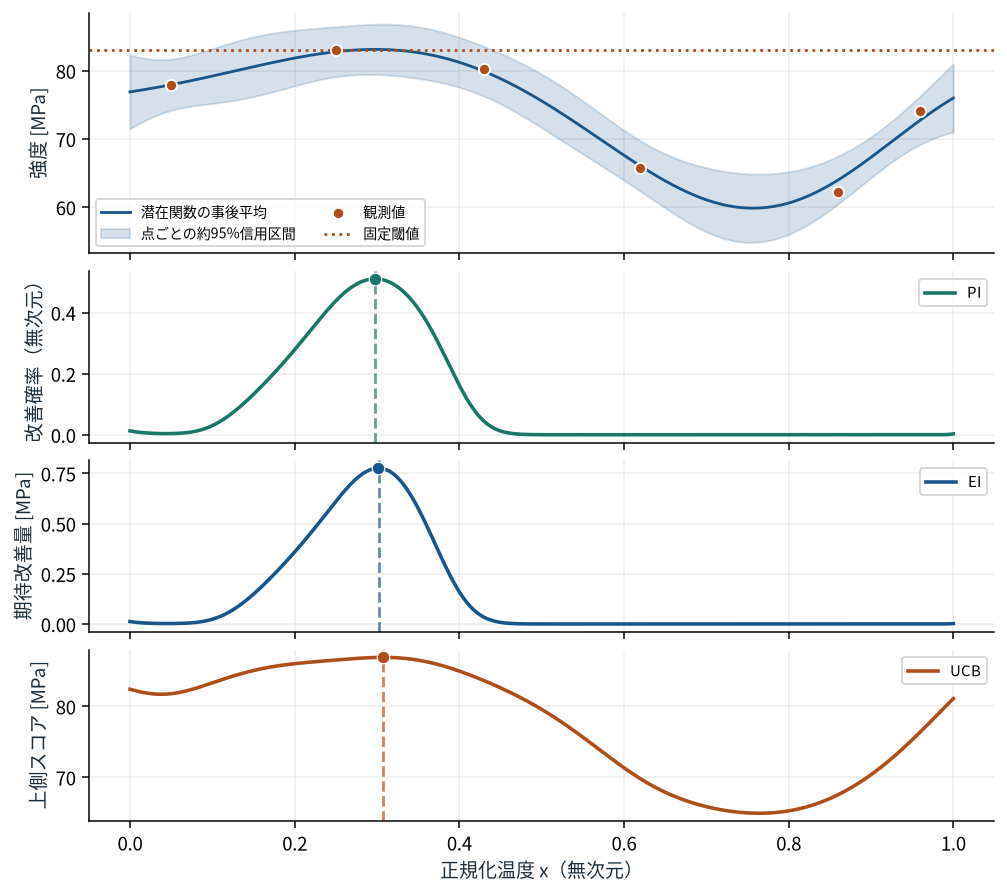

In [2]:
with torch.no_grad():
    posterior = model.posterior(grid)
    mean = posterior.mean.squeeze(-1)
    sd = posterior.variance.sqrt().squeeze(-1)
x_axis = grid.squeeze(-1)

fig, axes = plt.subplots(4, 1, figsize=(7.35, 6.5), sharex=True, layout="constrained",
                         gridspec_kw={"height_ratios": [1.4, 1, 1, 1]})
axes[0].plot(x_axis, mean, color=BLUE, label="潜在関数の事後平均")
axes[0].fill_between(x_axis, mean - 1.96 * sd, mean + 1.96 * sd,
                     color=BLUE, alpha=0.18, label="点ごとの約95%信用区間")
axes[0].scatter(train_x, train_y, color=ORANGE, edgecolor="white", zorder=3, label="観測値")
axes[0].axhline(best_f, color=ORANGE, linestyle=":", label="固定閾値")
axes[0].set_ylabel("強度 [MPa]")
axes[0].legend(ncols=2, fontsize=7.5, loc="lower left")
for ax, (label, display, _, unit, color) in zip(axes[1:], items):
    with torch.no_grad():
        score = display(choices)
        xc = rows[label]["optimized_x"]
        yc = display(torch.tensor([[[xc]]], dtype=DTYPE)).item()
    ax.plot(x_axis, score, color=color, linewidth=1.9, label=label)
    ax.axvline(rows[label]["grid_max_x"], color=color, linestyle="--", alpha=0.68)
    ax.scatter(xc, yc, color=color, edgecolor="white", linewidth=0.6, s=45, zorder=4)
    ax.set_ylabel(unit)
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("正規化温度 x（無次元）")
save_figure(fig, "ch05_acquisition_comparison")

## 5.3 二候補の判断を比べる
$80$ MPaを超える面積がPIです。EIは、同じ右側の密度を基準を超えた量で重み付けした積分です。先にどの候補の面積が広いかを考え、次に超えた場合の強度の伸びを見て、順位を予想してみましょう。ここでは説明のために平均と標準偏差を指定します。

A: PI = 0.933, EI = 1.529 MPa, 改善した場合の平均 = 1.639 MPa
B: PI = 0.434, EI = 1.927 MPa, 改善した場合の平均 = 4.442 MPa


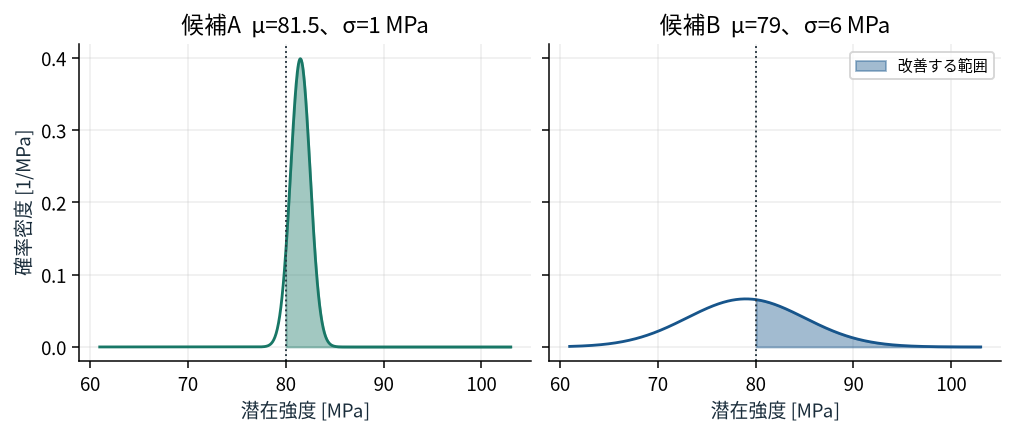

In [3]:
example_threshold = 80.0
densities = (("A", 81.5, 1.0, GREEN), ("B", 79.0, 6.0, BLUE))
strength = np.linspace(61, 103, 700)
example = {}
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.1), sharex=True, sharey=True, layout="constrained")
for ax, (name, mu, sigma, color) in zip(axes, densities):
    distribution = norm(loc=mu, scale=sigma)
    probability = distribution.sf(example_threshold)
    expected_improvement = quad(
        lambda value: (value - example_threshold) * distribution.pdf(value),
        example_threshold, np.inf,
    )[0]
    z_value = (mu - example_threshold) / sigma
    closed_form = (mu - example_threshold) * norm.cdf(z_value) + sigma * norm.pdf(z_value)
    np.testing.assert_allclose(expected_improvement, closed_form, rtol=1e-10)
    example[name] = {
        "mean_mpa": mu,
        "sd_mpa": sigma,
        "pi": probability,
        "ei_mpa": expected_improvement,
        "conditional_improvement_mpa": expected_improvement / probability,
    }
    density = distribution.pdf(strength)
    ax.plot(strength, density, color=color)
    ax.fill_between(strength, density, where=strength >= example_threshold,
                    interpolate=True, color=color, alpha=0.4, label="改善する範囲")
    ax.axvline(example_threshold, color="#273640", linestyle=":", linewidth=1)
    ax.set_title(f"候補{name}  μ={mu:g}、σ={sigma:g} MPa")
    ax.set_xlabel("潜在強度 [MPa]")
    print(f"{name}: PI = {probability:.3f}, EI = {expected_improvement:.3f} MPa, "
          f"改善した場合の平均 = {expected_improvement / probability:.3f} MPa")
axes[0].set_ylabel("確率密度 [1/MPa]")
axes[1].legend(loc="upper right", fontsize=8)
assert example["A"]["pi"] > example["B"]["pi"]
assert example["B"]["ei_mpa"] > example["A"]["ei_mpa"]
save_figure(fig, "ch05_improvement_tails")


## 5.3 EIの閉形式を数値積分と公開APIに照合
$z=(\mu-b)/\sigma$ とすると、正の標準偏差で EI は $\sigma[z\Phi(z)+\phi(z)]$ です。標準正規変数 $t$ に関する積分 $\sigma\int_{-z}^{\infty}(z+t)\phi(t)\,dt$ でも求まります。グリッドのうち $-5\le z\le 5$ の点を抽出して照合します。候補の探索には前節と同じ既存APIを使います。

In [4]:
z_all = (mean - best_f) / sd
mask = (z_all >= -5) & (z_all <= 5)
z = z_all[mask].numpy()
sigma = sd[mask].numpy()
assert z.size > 20
closed = sigma * (z * norm.cdf(z) + norm.pdf(z))
integrated = np.array([
    s * quad(lambda t: (z_i + t) * norm.pdf(t), -z_i, np.inf, epsabs=1e-13)[0]
    for z_i, s in zip(z, sigma)
])
with torch.no_grad():
    library_ei = ei(choices[mask]).numpy()
    library_log_ei = log_ei(choices[mask]).numpy()
    library_pi = pi(choices[mask]).numpy()

np.testing.assert_allclose(library_pi, norm.cdf(z), rtol=1e-8, atol=1e-12)
np.testing.assert_allclose(closed, integrated, rtol=1e-8, atol=1e-11)
np.testing.assert_allclose(closed, library_ei, rtol=1e-8, atol=1e-11)
np.testing.assert_allclose(np.log(closed), library_log_ei, rtol=1e-8, atol=1e-10)
print("照合したグリッド点数:", len(z))
print("閉形式と数値積分の最大絶対差 [MPa]:", np.max(np.abs(closed - integrated)))

照合したグリッド点数: 227
閉形式と数値積分の最大絶対差 [MPa]: 1.4655859859047382e-11


## 5.4–5.5 UCB係数と数値の裾を調べる
UCB の式は $\mu+\sqrt{\beta}\sigma$ です。係数を変え、候補位置の変化を確認します。次に入力を固定し、閾値を上げて $z$ を負にします。生の EI が 0 に丸まった点は、対数を計算できないので折れ線には表示しません。

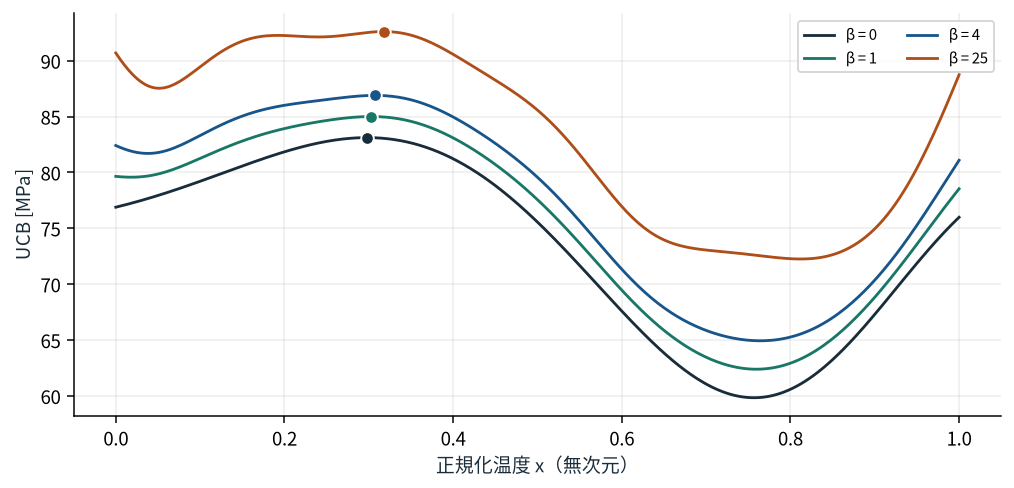

In [5]:
beta_rows = {}
fig, ax = plt.subplots(figsize=(7.4, 3.5), layout="constrained")
for beta, color in zip((0.0, 1.0, 4.0, 25.0), (INK, GREEN, BLUE, ORANGE)):
    score = UpperConfidenceBound(model, beta=beta)
    point, value = optimize_acqf(score, bounds, q=1, num_restarts=8, raw_samples=128,
                                 options={"seed": 2026})
    with torch.no_grad():
        grid_score = score(choices)
    ax.plot(x_axis, grid_score, color=color, label=f"β = {beta:g}")
    ax.scatter(point.item(), value.item(), color=color, edgecolor="white", zorder=4, s=45)
    beta_rows[f"{beta:g}"] = point.item()
ax.set(xlabel="正規化温度 x（無次元）", ylabel="UCB [MPa]")
ax.legend(fontsize=8, ncols=2)
save_figure(fig, "ch05_ucb_sensitivity")

第4章と同じ x = 0.50: μ = 75.56 MPa, σ = 2.00 MPa
z = -3.746, PI = 9e-05
{
  "threshold_mpa": 83.06292043343063,
  "prediction_grid_midpoint_pi": 8.999547559501317e-05,
  "prediction_grid_midpoint_z": -3.745561212951191,
  "prediction_grid_midpoint_mean_mpa": 75.55802787974477,
  "prediction_grid_midpoint_latent_sd_mpa": 2.0036763857271556,
  "observations_mpa": [
    77.92536345054386,
    83.06292043343063,
    80.2427772717856,
    65.7292665267901,
    62.27232319841271,
    74.10807719569486
  ],
  "worked_example": {
    "A": {
      "mean_mpa": 81.5,
      "sd_mpa": 1.0,
      "pi": 0.9331927987311419,
      "ei_mpa": 1.5293067937626053,
      "conditional_improvement_mpa": 1.6387897504588516
    },
    "B": {
      "mean_mpa": 79.0,
      "sd_mpa": 6.0,
      "pi": 0.43381616738909634,
      "ei_mpa": 1.9268221292225431,
      "conditional_improvement_mpa": 4.4415636715870646
    }
  },
  "candidates": {
    "PI": {
      "grid_max_x": 0.2975,
      "optimized_x": 0.2977311966018649

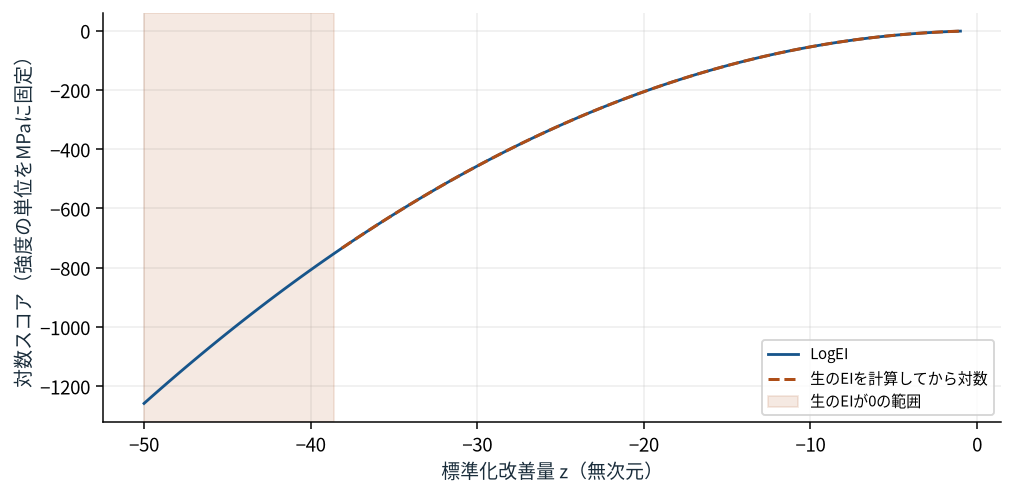

In [6]:
tail_point = torch.tensor([[[0.50]]], dtype=DTYPE)
tail_z = np.linspace(-50, -1, 100)
with torch.no_grad():
    p = model.posterior(tail_point)
    tail_mean, tail_sd = p.mean.item(), p.variance.sqrt().item()
    midpoint_pi = pi(tail_point).item()
midpoint_z = (tail_mean - best_f.item()) / tail_sd
np.testing.assert_allclose(midpoint_pi, norm.cdf(midpoint_z), rtol=1e-9)
print(f"第4章と同じ x = 0.50: μ = {tail_mean:.2f} MPa, σ = {tail_sd:.2f} MPa")
print(f"z = {midpoint_z:.3f}, PI = {midpoint_pi:.3g}")
with torch.no_grad():
    ei_tail, log_ei_tail = [], []
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=NumericsWarning)
        for z_i in tail_z:
            threshold = tail_mean - z_i * tail_sd
            ei_tail.append(ExpectedImprovement(model, best_f=threshold)(tail_point).item())
            log_ei_tail.append(LogExpectedImprovement(model, best_f=threshold)(tail_point).item())

ei_tail = np.array(ei_tail)
log_ei_tail = np.array(log_ei_tail)
positive = ei_tail > 0
assert (~positive).any() and positive.any() and np.isfinite(log_ei_tail).all()
fig, ax = plt.subplots(figsize=(7.4, 3.55), layout="constrained")
ax.plot(tail_z, log_ei_tail, color=BLUE, label="LogEI")
ax.plot(tail_z[positive], np.log(ei_tail[positive]), "--", color=ORANGE,
        linewidth=1.6, label="生のEIを計算してから対数")
last_zero = float(tail_z[~positive].max())
ax.axvspan(tail_z.min(), last_zero, alpha=0.12, color=ORANGE, label="生のEIが0の範囲")
ax.set(xlabel="標準化改善量 z（無次元）", ylabel="対数スコア（強度の単位をMPaに固定）")
ax.legend(loc="lower right", fontsize=8)
save_figure(fig, "ch05_logei_tail")

QUALITY.mkdir(exist_ok=True)
metrics = {
    "threshold_mpa": best_f.item(),
    "prediction_grid_midpoint_pi": midpoint_pi,
    "prediction_grid_midpoint_z": midpoint_z,
    "prediction_grid_midpoint_mean_mpa": tail_mean,
    "prediction_grid_midpoint_latent_sd_mpa": tail_sd,
    "observations_mpa": train_y.squeeze(-1).tolist(),
    "worked_example": example,
    "candidates": rows,
    "ucb_beta_candidates_x": beta_rows,
    "quadrature_comparison_count": int(len(z)),
    "quadrature_max_abs_error_mpa": float(np.max(np.abs(closed - integrated))),
    "botorch_ei_max_abs_error_mpa": float(np.max(np.abs(closed - library_ei))),
    "botorch_logei_max_abs_error": float(np.max(np.abs(np.log(closed) - library_log_ei))),
    "tail_raw_ei_zero_count": int((~positive).sum()),
    "tail_total_count": int(len(tail_z)),
    "tail_last_zero_z": last_zero,
    "logei_at_z_minus_50": float(log_ei_tail[0]),
}
(QUALITY / "ch05_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
print(json.dumps(metrics, indent=2))

## 章末演習
1. **確認。** $b=80$ MPa、候補Aを $(\mu,\sigma)=(81,0.5)$、候補Bを $(79,4)$ として、PI・EI・$\beta=4$ のUCBで順位をつけましょう。
2. **操作。** UCBの $\beta$ を 0、1、4、25 に変えて、候補位置と事後標準偏差の関係を説明しましょう。
3. **操作。** 問題1の基準を $b=78$ と $b=82$ に変え、PIとEIそれぞれの順位を調べましょう。
4. **発展。** 観測ノイズが大きい場合に、固定した観測最大値を基準にするとどんな影響があるかを考えましょう。

**答え合わせ。** 付録の「第5章」で、順位と比較の根拠を照合できます。